c:\Users\ksaij\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Saved Prediction.csv successfully!


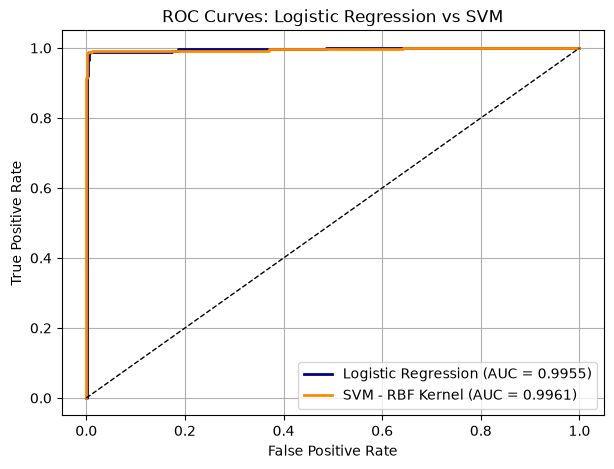

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc

# 1. Load Datasets
X_train = pd.read_csv("X_train_processed.csv")
X_test = pd.read_csv("X_test_processed.csv")
y_train = pd.read_csv("y_train.csv").values.ravel()
y_test = pd.read_csv("y_test.csv").values.ravel()

# 2. Train Both Models
lr = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)
svm = SVC(kernel='rbf', probability=True, random_state=42).fit(X_train, y_train)

# 3. Generate Predictions & Output CSV
pred_lr = lr.predict(X_test)
pred_svm = svm.predict(X_test)
prob_lr = lr.predict_proba(X_test)[:, 1]
prob_svm = svm.predict_proba(X_test)[:, 1]

df_predictions = pd.DataFrame({
    'Actual_Wine_Type': y_test,
    'LR_Prediction': pred_lr,
    'LR_Probability_Red': prob_lr,
    'SVM_Prediction': pred_svm,
    'SVM_Probability_Red': prob_svm
})
df_predictions.to_csv("Prediction.csv", index=False)
print("Saved Prediction.csv successfully!")

# 4. Comparative ROC-AUC Plot
fpr_lr, tpr_lr, _ = roc_curve(y_test, prob_lr)
fpr_svm, tpr_svm, _ = roc_curve(y_test, prob_svm)

plt.figure(figsize=(7, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc(fpr_lr, tpr_lr):.4f})", color='navy', lw=2)
plt.plot(fpr_svm, tpr_svm, label=f"SVM - RBF Kernel (AUC = {auc(fpr_svm, tpr_svm):.4f})", color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Logistic Regression vs SVM")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()